In [34]:
import random

def k_means(X, k,  max_iter = 100):

    # 1. Randomly initialize k centroids from the data points
    # 2. Assign each data point to the nearest centroid
    # 3. Update centroids based on assigned data points
    # 4. Repeat steps 2-3 until convergence (no change in assignments of data points to centroids)

    n = len(X)

    # Randomly initialize k centroids from the data points
    random_indices = random.sample(range(n), k)
    centroids = X[random_indices].copy()

    for _ in range(max_iter):

        # Step 2: Assign each data point to the nearest centroid
        assignments = []
        for x in X:
            min_distance = float('inf')
            nearest_centroid = None
            for c in centroids:
                # Calculate distance between x and c (e.g., Euclidean distance)
                distance = ((x - c) ** 2).sum() ** 0.5
                # Assign x to the nearest centroid based on the calculated distance
                if distance < min_distance:
                    min_distance = distance
                    nearest_centroid = c
            assignments.append(nearest_centroid)

        # Step 3: Update centroids based on assigned data points
        new_centroids = []
        for c in centroids:
            assigned_points = [x for x, a in zip(X, assignments) if (a == c).all()]
            if assigned_points:
                new_centroid = sum(assigned_points) / len(assigned_points)
                new_centroids.append(new_centroid)
            else:
                # If no points are assigned to this centroid, keep it unchanged
                new_centroids.append(c)

        # Check for convergence (if centroids do not change)
        if all((new_c == old_c).all() for new_c, old_c in zip(new_centroids, centroids)):
            break
        centroids = new_centroids

    return centroids, assignments


Centroids:
 [[-5.09307324  4.97460872]
 [ 0.01680616  0.10280987]
 [ 4.98127847  5.18274747]]


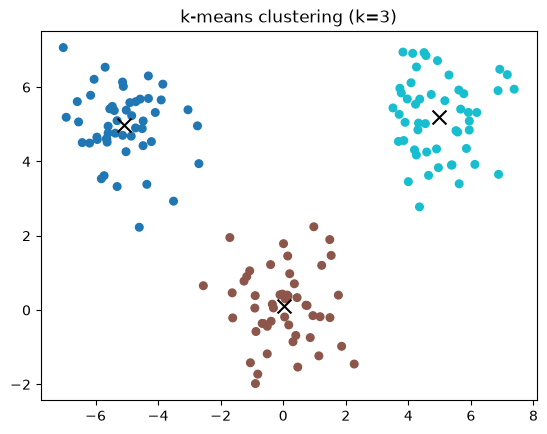

In [36]:
import numpy as np

import matplotlib.pyplot as plt

# create synthetic dataset with 3 clusters
np.random.seed(0)
X = np.vstack([
    np.random.randn(50, 2) + np.array([0, 0]),
    np.random.randn(50, 2) + np.array([5, 5]),
    np.random.randn(50, 2) + np.array([-5, 5]),
])

# run k-means from the existing cell
centroids, assignments = k_means(X, k=3, max_iter=100)

centroids = np.array(centroids)

# convert assignments (centroid arrays) to integer labels
labels = []
for a in assignments:
    matched = False
    for i, c in enumerate(centroids):
        if np.allclose(a, c):
            labels.append(i)
            matched = True
            break
    if not matched:
        labels.append(int(np.argmin(np.linalg.norm(centroids - a, axis=1))))

print("Centroids:\n", centroids)

# plot results
plt.scatter(X[:, 0], X[:, 1], c=labels, cmap='tab10', s=30)
plt.scatter(centroids[:, 0], centroids[:, 1], c='k', marker='x', s=100)
plt.title("k-means clustering (k=3)")
plt.show()

In [1]:
import numpy as np

class KMeans:

    def __init__(self, k, max_iter=100, tol=1e-4):
        self.k = k
        self.max_iter = max_iter
        self.tol = tol
        self.centroids = None

    def fit(self, X):

        n = X.shape[0]

        # 1. Randomly initialize k centroids
        indices = np.random.choice(n, self.k, replace=False)
        self.centroids = X[indices].copy()

        for _ in range(self.max_iter):

            # 2. Distance of every point from every centroid
            distances = np.linalg.norm(
                X[:, None, :] - self.centroids[None, :, :],
                axis=2
            )

            # 3. Assign each point to nearest centroid
            labels = np.argmin(distances, axis=1)

            # 4. Recalculate centroids
            new_centroids = []

            for i in range(self.k):

                points = X[labels == i]

                # Handle empty cluster
                if len(points) == 0:
                    new_centroid = self.centroids[i]
                else:
                    new_centroid = np.mean(points, axis=0)

                new_centroids.append(new_centroid)

            new_centroids = np.array(new_centroids)

            # 5. Check convergence
            shift = np.linalg.norm(
                new_centroids - self.centroids,
                axis=1
            ).max()

            self.centroids = new_centroids

            if shift < self.tol:
                break

        return self

    def predict(self, X):

        distances = np.linalg.norm(
            X[:, None, :] - self.centroids[None, :, :],
            axis=2
        )

        return np.argmin(distances, axis=1)

    def fit_predict(self, X):
        self.fit(X)
        return self.predict(X)